# Geometric Morphometric Data Augmentation & Imbalance Classification
## Experiment 2: Geometrically Augmented Training Data (707 SAM, 707 MAM, 707 ONC) vs Pristine Real Out-of-Sample Validation

### 📌 Study Overview & Experimental Objective
* **Training Dataset**: Geometric Transformation Augmented Dataset (`final_balanced_dataset_geometric_augmented.csv`) containing 707 ONC, 707 MAM, and 707 geometrically augmented SAM specimens.
* **Testing & Validation Dataset**: Pristine Real Dataset (`final_cleaned_dataset_full.csv`) containing authentic real-world specimens (5279 ONC, 707 MAM, 217 SAM) for strictly out-of-sample validation.
* **Feature Selection**: Geometric Morphometric Procrustes Coordinates excluding noisy/collinear landmarks (**LM11**, **LM21**, **LM22**) $\rightarrow$ **41 total features** (`GPA_X1`..`GPA_Y20`, `Centroid_Size`, `age_month`, `gender_num`).
* **Primary Metric Focus**: **SAM Recall**, **SAM Precision**, **SAM F1**, **Macro F1**, and **Balanced Accuracy** across both 5-Fold Cross-Validation and Pristine Out-of-Sample Testing.

---
### 🔄 Experimental Pipeline
```text
┌────────────────────────────────────────────────────────┐
│  Geometric Transformation Augmented Training Dataset   │
│       (707 SAM, 707 MAM, 707 ONC - 2121 Total)        │
└──────────────────────────┬─────────────────────────────┘
                           │
                           ▼
┌────────────────────────────────────────────────────────┐
│       Stratified 5-Fold Cross-Validation Folds         │
│          + Full XGBoost Classifier Training            │
└──────────────────────────┬─────────────────────────────┘
                           │
                           ▼
┌────────────────────────────────────────────────────────┐
│     Strict Out-of-Sample Testing & Validation          │
│       Pristine Real Dataset (707 ONC, 707 MAM, 217 SAM) │
└────────────────────────────────────────────────────────┘
```

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, f1_score, recall_score, precision_score, balanced_accuracy_score, confusion_matrix
from xgboost import XGBClassifier
from imblearn.over_sampling import RandomOverSampler
import warnings
warnings.filterwarnings('ignore')

# Global Reproducibility Seed
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("✅ Libraries loaded successfully.")

✅ Libraries loaded successfully.


In [2]:
# Load Training Dataset (Geometric Transformation Augmented) and Testing & Validation Dataset (Pristine Real Data)
train_path = r"e:\ap-govt-EDA-model-tainning-testing\GM_out_of_sample_classification-main\GM_out_of_sample_classification-ap-govt\Data-Augmentation-by-Geometric Transformation Modeling\final_balanced_dataset_geometric_augmented.csv"
test_path = r"e:\ap-govt-EDA-model-tainning-testing\GM_out_of_sample_classification-main\GM_out_of_sample_classification-ap-govt\outliers_quality_of_data_extraction\final_cleaned_dataset_full.csv"

# Fallback relative paths if needed
if not os.path.exists(train_path):
    train_path = os.path.join(os.path.dirname(os.getcwd()), "Data-Augmentation-by-Geometric Transformation Modeling", "final_balanced_dataset_geometric_augmented.csv")
if not os.path.exists(test_path):
    test_path = os.path.join(os.path.dirname(os.getcwd()), "outliers_quality_of_data_extraction", "final_cleaned_dataset_full.csv")

df_train = pd.read_csv(train_path)
df_test = pd.read_csv(test_path)

# Encode Gender for both datasets
df_train['gender_num'] = df_train['gender'].map({'M': 0, 'F': 1, 'Male': 0, 'Female': 1}).fillna(0)
df_test['gender_num'] = df_test['gender'].map({'M': 0, 'F': 1, 'Male': 0, 'Female': 1}).fillna(0)

# Selected Feature Columns (19 GPA Landmarks + Centroid Size + Age + Gender)
feature_cols = [c for c in df_train.columns if c.startswith('GPA_')] + ['Centroid_Size', 'age_month', 'gender_num']
target_col = 'Class_Type'

print(f"📊 Training Dataset Shape (Geometric Augmented): {df_train.shape}")
print("🏷️ Training Dataset Class Distribution:")
print(df_train[target_col].value_counts())

print(f"\n📊 Testing & Validation Dataset Shape (Pristine Real): {df_test.shape}")
print("🏷️ Testing Dataset Class Distribution:")
print(df_test[target_col].value_counts())

print(f"\n🧬 Selected Feature Count: {len(feature_cols)} (38 GPA Coordinates + 3 Demographics)")

📊 Training Dataset Shape (Geometric Augmented): (6693, 104)
🏷️ Training Dataset Class Distribution:
Class_Type
onc    5279
mam     707
sam     707
Name: count, dtype: int64

📊 Testing & Validation Dataset Shape (Pristine Real): (6203, 104)
🏷️ Testing Dataset Class Distribution:
Class_Type
onc    5279
mam     707
sam     217
Name: count, dtype: int64

🧬 Selected Feature Count: 41 (38 GPA Coordinates + 3 Demographics)


In [3]:
# Inspect & Print Geometrically Augmented Dataset Details in Separate Cell
df_sam_all = df_train[df_train['Class_Type'] == 'sam'].copy()
df_sam_real = df_sam_all[~df_sam_all['File_Name'].astype(str).str.startswith('SYNTH_SAM')].copy()
df_sam_aug = df_sam_all[df_sam_all['File_Name'].astype(str).str.startswith('SYNTH_SAM')].copy()

print("=================================================================")
print("🧩 GEOMETRIC TRANSFORMATION AUGMENTED DATASET DETAILS")
print("=================================================================")
print(f"📁 Source File: final_balanced_dataset_geometric_augmented.csv")
print(f"📊 Total Dataset Specimens: {len(df_train)}")
print(f"🏷️ Class Breakdown:")
print(f"   • ONC (Optimal Nutritional Condition) : {len(df_train[df_train['Class_Type'] == 'onc'])} specimens")
print(f"   • MAM (Moderate Acute Malnutrition)    : {len(df_train[df_train['Class_Type'] == 'mam'])} specimens")
print(f"   • SAM (Severe Acute Malnutrition)      : {len(df_sam_all)} total ({len(df_sam_real)} real + {len(df_sam_aug)} geometrically augmented)")
print("=================================================================\n")

print("🔍 Preview of Geometrically Augmented SAM Specimens (First 10 Rows):")
preview_cols = ['File_Name', 'Individual', 'Class_Type', 'age_month', 'gender', 'Centroid_Size', 'GPA_X1', 'GPA_Y1', 'GPA_X2', 'GPA_Y2']
print(df_sam_aug[preview_cols].head(10).to_string(index=False))

print("\n-----------------------------------------------------------------")
print("📈 Descriptive Statistics of Geometrically Augmented Features:")
print("-----------------------------------------------------------------")
aug_stats = df_sam_aug[['Centroid_Size', 'age_month', 'GPA_X1', 'GPA_Y1', 'GPA_X2', 'GPA_Y2']].describe()
print(aug_stats.to_string())
print("=================================================================")

🧩 GEOMETRIC TRANSFORMATION AUGMENTED DATASET DETAILS
📁 Source File: final_balanced_dataset_geometric_augmented.csv
📊 Total Dataset Specimens: 6693
🏷️ Class Breakdown:
   • ONC (Optimal Nutritional Condition) : 5279 specimens
   • MAM (Moderate Acute Malnutrition)    : 707 specimens
   • SAM (Severe Acute Malnutrition)      : 707 total (217 real + 490 geometrically augmented)

🔍 Preview of Geometrically Augmented SAM Specimens (First 10 Rows):
             File_Name     Individual Class_Type  age_month gender  Centroid_Size    GPA_X1   GPA_Y1    GPA_X2    GPA_Y2
SYNTH_SAM_GEO_0001.png SYNTH_SAM_0001        sam      30.40 Female      34.017691 -0.404359 0.108988 -0.033480 -0.028242
SYNTH_SAM_GEO_0002.png SYNTH_SAM_0002        sam      30.40 Female      36.119459 -0.419936 0.110396 -0.042179 -0.013954
SYNTH_SAM_GEO_0003.png SYNTH_SAM_0003        sam      47.80   Male      46.314928 -0.385937 0.092024 -0.029995 -0.008586
SYNTH_SAM_GEO_0004.png SYNTH_SAM_0004        sam      32.22   Male   

In [4]:
# Experiment 2 Setup: Balanced Training Matrix & Pristine Out-of-Sample Test Matrix

# 1. Prepare Training Subset (707 ONC, 707 MAM, 707 Geometrically Augmented SAM)
df_tr_sam = df_train[df_train['Class_Type'] == 'sam']
df_tr_mam = df_train[df_train['Class_Type'] == 'mam']
df_tr_onc = df_train[df_train['Class_Type'] == 'onc'].sample(n=min(707, len(df_train[df_train['Class_Type'] == 'onc'])), random_state=RANDOM_STATE)

df_exp2_train = pd.concat([df_tr_onc, df_tr_mam, df_tr_sam]).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
X_train = df_exp2_train[feature_cols].values
y_train = df_exp2_train['Class_Type'].map({'onc': 0, 'mam': 1, 'sam': 2}).values

# 2. Prepare Testing & Validation Subset (707 ONC, 707 MAM, 217 Pristine Real SAM)
df_te_sam = df_test[df_test['Class_Type'] == 'sam']
df_te_mam = df_test[df_test['Class_Type'] == 'mam']
df_te_onc = df_test[df_test['Class_Type'] == 'onc'].sample(n=min(707, len(df_test[df_test['Class_Type'] == 'onc'])), random_state=RANDOM_STATE)

df_exp2_test = pd.concat([df_te_onc, df_te_mam, df_te_sam]).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
X_test = df_exp2_test[feature_cols].values
y_test = df_exp2_test['Class_Type'].map({'onc': 0, 'mam': 1, 'sam': 2}).values

# Alias for downstream functions
df_exp2 = df_exp2_train

print(f"🏋️ Training Dataset Matrix: {X_train.shape} | Class distribution:")
print(df_exp2_train['Class_Type'].value_counts().to_dict())

print(f"\n🧪 Testing & Validation Matrix: {X_test.shape} | Class distribution:")
print(df_exp2_test['Class_Type'].value_counts().to_dict())

🏋️ Training Dataset Matrix: (2121, 41) | Class distribution:
{'sam': 707, 'onc': 707, 'mam': 707}

🧪 Testing & Validation Matrix: (1631, 41) | Class distribution:
{'mam': 707, 'onc': 707, 'sam': 217}


📐 LANDMARK WIREFRAME CONNECTIONS BY CLASS
Landmark Anatomical Connections:
 • Upper Contour : LM1 -> LM12 -> LM14 -> LM16 -> LM18 -> LM10 -> LM8 -> LM6 -> LM20
 • Lower Contour : LM4 -> LM13 -> LM15 -> LM17 -> LM9  -> LM7 -> LM5 -> LM19
 • Cross-Sections: [LM12-LM4], [LM14-LM13], [LM16-LM15], [LM18-LM17], [LM10-LM9], [LM8-LM7], [LM6-LM5]
 • Shoulder Edge : [LM1-LM4]  | Wrist Edge: [LM20-LM3-LM19] | Central Axis: [LM2-LM3]



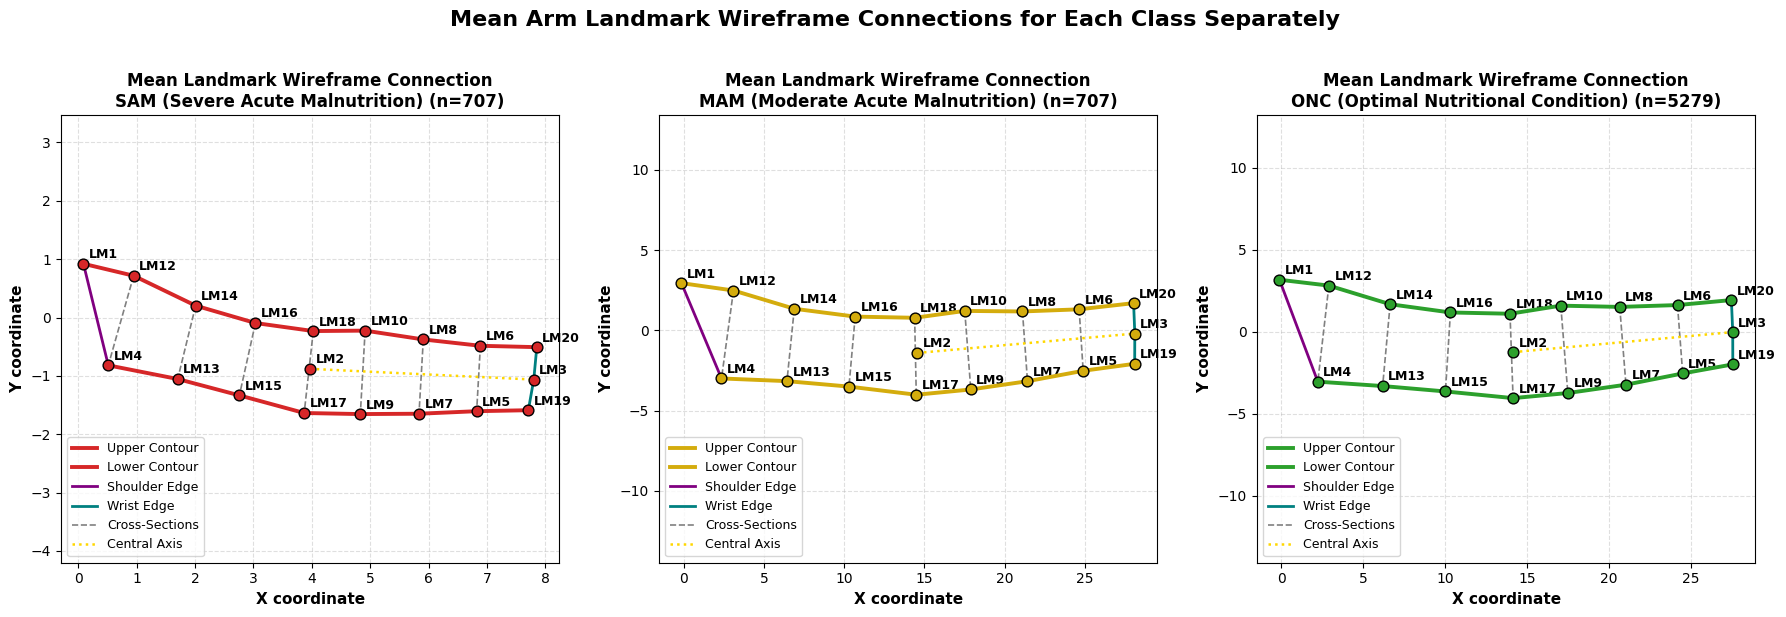

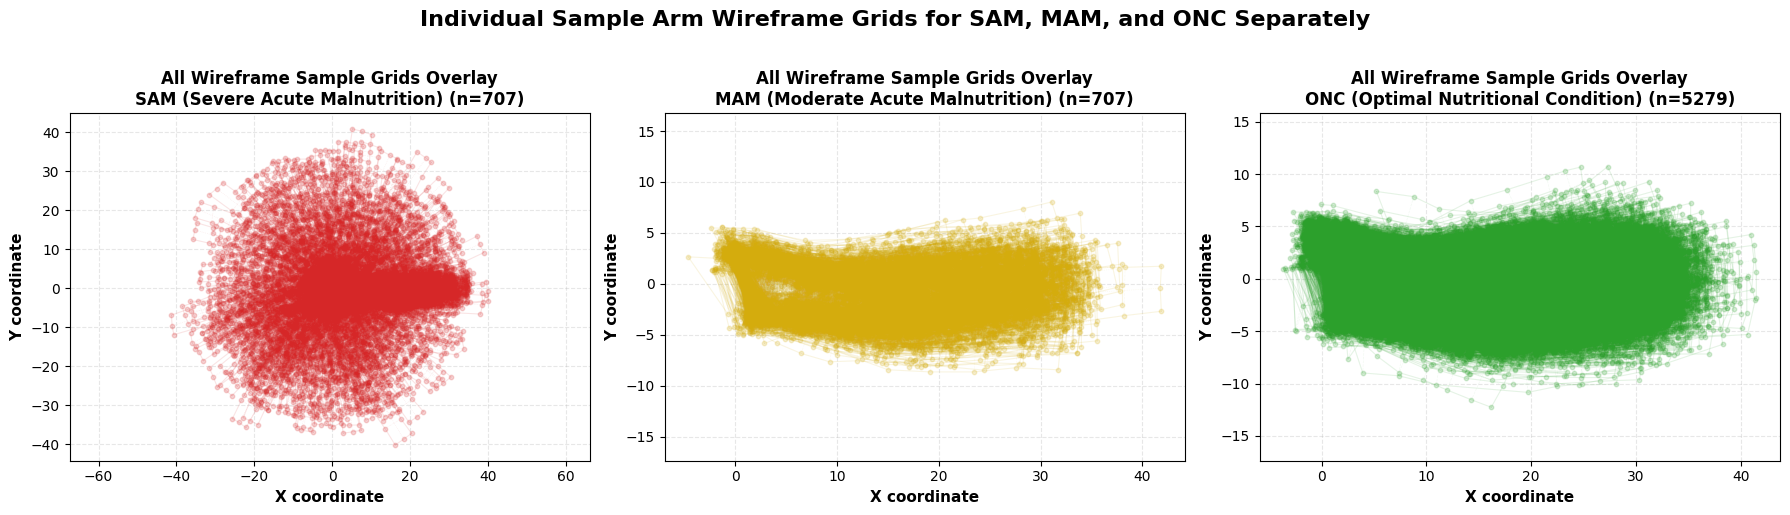

In [5]:
# -----------------------------------------------------------------------------
# DEDICATED CELL: Wireframe Connections for SAM, MAM, and ONC Classes Separately
# -----------------------------------------------------------------------------

landmark_ids = [lid for lid in range(1, 23) if f'X{lid}' in df_exp2.columns]
id_to_idx = {lid: i for i, lid in enumerate(landmark_ids)}
K = len(landmark_ids)

upper_contour_ids = [1, 12, 14, 16, 18, 10, 8, 6, 20]
upper_contour_idx = [id_to_idx[lid] for lid in upper_contour_ids if lid in id_to_idx]
lower_contour_ids = [4, 13, 15, 17, 9, 7, 5, 19]
lower_contour_idx = [id_to_idx[lid] for lid in lower_contour_ids if lid in id_to_idx]
shoulder_edge_idx = [id_to_idx[1], id_to_idx[4]] if (1 in id_to_idx and 4 in id_to_idx) else []
wrist_edge_idx = [id_to_idx[lid] for lid in [20, 3, 19] if lid in id_to_idx]
dashed_cross_ids = [[12, 4], [14, 13], [16, 15], [18, 17], [10, 9], [8, 7], [6, 5]]
dashed_cross_idx = [[id_to_idx[lid] for lid in seg if lid in id_to_idx] for seg in dashed_cross_ids]
midline_idx = [id_to_idx[lid] for lid in [2, 3] if lid in id_to_idx]

def plot_arm_wireframe(ax, shapes, color='black', alpha_solid=0.8, alpha_dashed=0.4, 
                       lw_solid=1.5, lw_dashed=1.0, alpha_scatter=0.6, s=20, 
                       label=None, show_labels=True, monochrome=True):
    shapes_arr = np.asarray(shapes)
    if shapes_arr.ndim == 2:
        shapes_arr = shapes_arr[np.newaxis, :, :]
    elif shapes_arr.ndim == 3:
        if shapes_arr.shape[1] == 2 and shapes_arr.shape[0] != 2:
            shapes_arr = np.transpose(shapes_arr, (2, 0, 1))

    N_samples = shapes_arr.shape[0]
    c_upper = color if monochrome else 'red'
    c_lower = color if monochrome else 'blue'
    c_shoulder = color if monochrome else 'purple'
    c_wrist = color if monochrome else 'green'
    c_cross = color if monochrome else 'gray'
    c_midline = color if monochrome else 'gold'

    if alpha_scatter > 0 and s > 0:
        all_x = shapes_arr[:, :, 0].flatten()
        all_y = shapes_arr[:, :, 1].flatten()
        ax.scatter(all_x, all_y, color=color, alpha=alpha_scatter, s=s, zorder=3, label=label if label else None)

    for i in range(N_samples):
        sh = shapes_arr[i]
        if upper_contour_idx:
            ax.plot(sh[upper_contour_idx, 0], sh[upper_contour_idx, 1], color=c_upper, 
                    alpha=alpha_solid, linewidth=lw_solid, linestyle='-', zorder=5)
        if lower_contour_idx:
            ax.plot(sh[lower_contour_idx, 0], sh[lower_contour_idx, 1], color=c_lower, 
                    alpha=alpha_solid, linewidth=lw_solid, linestyle='-', zorder=5)
        if shoulder_edge_idx:
            ax.plot(sh[shoulder_edge_idx, 0], sh[shoulder_edge_idx, 1], color=c_shoulder, 
                    alpha=alpha_solid, linewidth=lw_solid, linestyle='-', zorder=5)
        if wrist_edge_idx:
            ax.plot(sh[wrist_edge_idx, 0], sh[wrist_edge_idx, 1], color=c_wrist, 
                    alpha=alpha_solid, linewidth=lw_solid, linestyle='-', zorder=5)
        for seg in dashed_cross_idx:
            ax.plot(sh[seg, 0], sh[seg, 1], color=c_cross, 
                    alpha=alpha_dashed, linewidth=lw_dashed, linestyle='--', zorder=4)
        if len(midline_idx) >= 2:
            ax.plot(sh[midline_idx, 0], sh[midline_idx, 1], color=c_midline, 
                    alpha=alpha_solid * 0.8, linewidth=lw_dashed, linestyle=':', zorder=4)

classes = ['sam', 'mam', 'onc']
class_titles = {
    'sam': 'SAM (Severe Acute Malnutrition)',
    'mam': 'MAM (Moderate Acute Malnutrition)',
    'onc': 'ONC (Optimal Nutritional Condition)'
}
class_colors = {'sam': '#d62728', 'mam': '#d4ac0d', 'onc': '#2ca02c'}

print("=================================================================")
print("📐 LANDMARK WIREFRAME CONNECTIONS BY CLASS")
print("=================================================================")
print("Landmark Anatomical Connections:")
print(" • Upper Contour : LM1 -> LM12 -> LM14 -> LM16 -> LM18 -> LM10 -> LM8 -> LM6 -> LM20")
print(" • Lower Contour : LM4 -> LM13 -> LM15 -> LM17 -> LM9  -> LM7 -> LM5 -> LM19")
print(" • Cross-Sections: [LM12-LM4], [LM14-LM13], [LM16-LM15], [LM18-LM17], [LM10-LM9], [LM8-LM7], [LM6-LM5]")
print(" • Shoulder Edge : [LM1-LM4]  | Wrist Edge: [LM20-LM3-LM19] | Central Axis: [LM2-LM3]")
print("=================================================================\n")

# Figure 1: Mean Landmark Wireframe Connections for SAM, MAM, and ONC Separately
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, cls in zip(axes, classes):
    df_cls = df_train[df_train['Class_Type'] == cls]
    shapes = np.zeros((len(df_cls), K, 2))
    for i in range(len(df_cls)):
        for lid_idx, lid in enumerate(landmark_ids):
            shapes[i, lid_idx, 0] = df_cls.iloc[i][f'X{lid}']
            shapes[i, lid_idx, 1] = df_cls.iloc[i][f'Y{lid}']
            
    mean_shape = np.mean(shapes, axis=0)
    
    if upper_contour_idx:
        ax.plot(mean_shape[upper_contour_idx, 0], mean_shape[upper_contour_idx, 1], color=class_colors[cls], linewidth=2.8, label='Upper Contour', zorder=5)
    if lower_contour_idx:
        ax.plot(mean_shape[lower_contour_idx, 0], mean_shape[lower_contour_idx, 1], color=class_colors[cls], linewidth=2.8, label='Lower Contour', zorder=5)
    if shoulder_edge_idx:
        ax.plot(mean_shape[shoulder_edge_idx, 0], mean_shape[shoulder_edge_idx, 1], color='purple', linewidth=2.0, label='Shoulder Edge', zorder=5)
    if wrist_edge_idx:
        ax.plot(mean_shape[wrist_edge_idx, 0], mean_shape[wrist_edge_idx, 1], color='teal', linewidth=2.0, label='Wrist Edge', zorder=5)
    for idx_seg, seg in enumerate(dashed_cross_idx):
        lbl = 'Cross-Sections' if idx_seg == 0 else None
        ax.plot(mean_shape[seg, 0], mean_shape[seg, 1], color='gray', linewidth=1.2, linestyle='--', label=lbl, zorder=4)
    if len(midline_idx) >= 2:
        ax.plot(mean_shape[midline_idx, 0], mean_shape[midline_idx, 1], color='gold', linewidth=1.8, linestyle=':', label='Central Axis', zorder=4)
        
    ax.scatter(mean_shape[:, 0], mean_shape[:, 1], color=class_colors[cls], s=60, edgecolors='black', linewidth=1.0, zorder=6)
    
    for idx, lid in enumerate(landmark_ids):
        ax.annotate(f'LM{lid}', (mean_shape[idx, 0], mean_shape[idx, 1]), xytext=(4, 4), textcoords='offset points', fontsize=9, fontweight='bold', color='black')

    ax.set_title(f"Mean Landmark Wireframe Connection\n{class_titles[cls]} (n={len(df_cls)})", fontsize=12, fontweight='bold')
    ax.set_xlabel('X coordinate', fontsize=11, fontweight='bold')
    ax.set_ylabel('Y coordinate', fontsize=11, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(loc='lower left', fontsize=9)
    ax.axis('equal')

plt.suptitle('Mean Arm Landmark Wireframe Connections for Each Class Separately', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Figure 2: Individual Sample Arm Wireframe Grids for SAM, MAM, and ONC Separately
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, cls in zip(axes, classes):
    df_cls = df_train[df_train['Class_Type'] == cls]
    shapes = np.zeros((len(df_cls), K, 2))
    for i in range(len(df_cls)):
        for lid_idx, lid in enumerate(landmark_ids):
            shapes[i, lid_idx, 0] = df_cls.iloc[i][f'X{lid}']
            shapes[i, lid_idx, 1] = df_cls.iloc[i][f'Y{lid}']
            
    plot_arm_wireframe(ax, shapes, color=class_colors[cls], alpha_solid=0.12, alpha_dashed=0.06, lw_solid=0.8, lw_dashed=0.5, alpha_scatter=0.20, s=10, show_labels=False)
    ax.set_title(f"All Wireframe Sample Grids Overlay\n{class_titles[cls]} (n={len(df_cls)})", fontsize=12, fontweight='bold')
    ax.set_xlabel('X coordinate', fontsize=11, fontweight='bold')
    ax.set_ylabel('Y coordinate', fontsize=11, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.axis('equal')

plt.suptitle('Individual Sample Arm Wireframe Grids for SAM, MAM, and ONC Separately', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

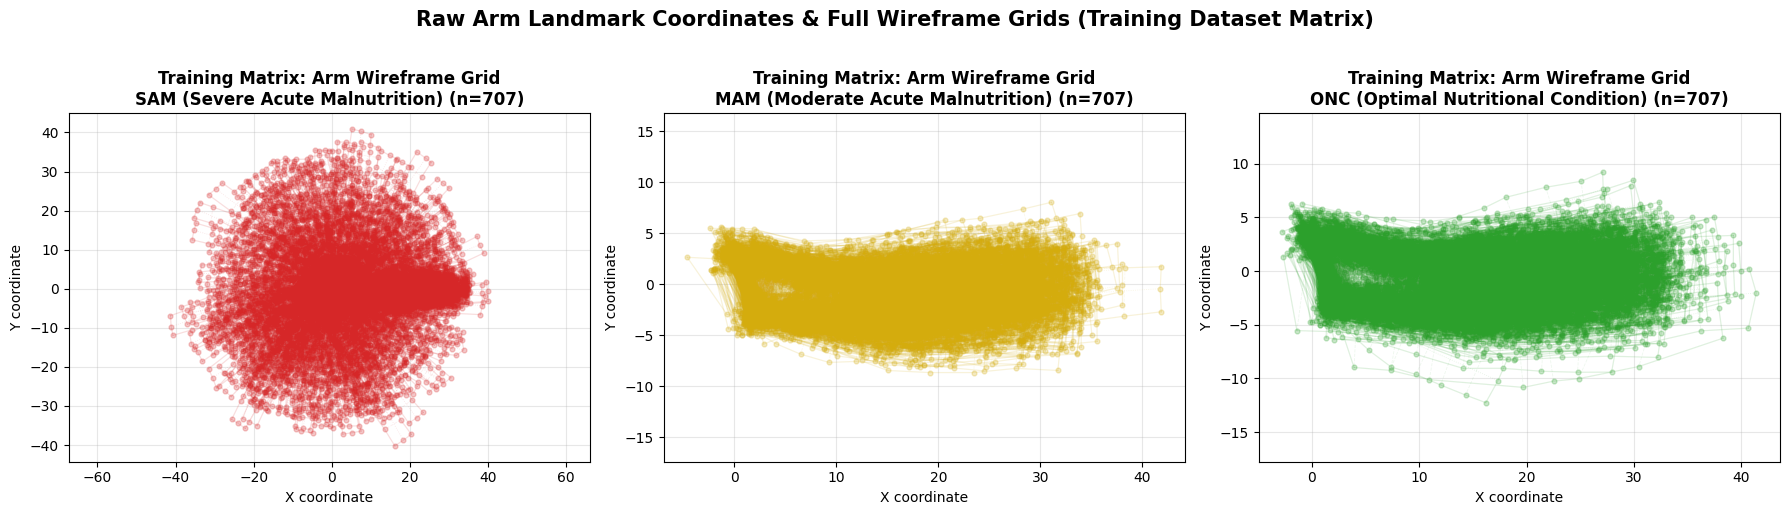

In [6]:
# Raw Landmark Scatter Plot & Arm Wireframes (Training Dataset Matrix)
shapes_raw = np.zeros((len(df_exp2), K, 2))
for i in range(len(df_exp2)):
    for lid_idx, lid in enumerate(landmark_ids):
        shapes_raw[i, lid_idx, 0] = df_exp2.iloc[i][f'X{lid}']
        shapes_raw[i, lid_idx, 1] = df_exp2.iloc[i][f'Y{lid}']

true_class = df_exp2['Class_Type'].values

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
classes = ['sam', 'mam', 'onc']
titles = ['SAM (Severe Acute Malnutrition)', 'MAM (Moderate Acute Malnutrition)', 'ONC (Optimal Nutritional Condition)']

for ax, cls, title in zip(axes, classes, titles):
    indices = np.where(true_class == cls)[0]
    plot_arm_wireframe(ax, shapes_raw[indices], color=class_colors[cls], 
                       alpha_solid=0.15, alpha_dashed=0.08, lw_solid=0.9, lw_dashed=0.6, alpha_scatter=0.25, s=12, show_labels=False)
    ax.set_title(f'Training Matrix: Arm Wireframe Grid\n{title} (n={len(indices)})', fontsize=12, fontweight='bold')
    ax.set_xlabel('X coordinate')
    ax.set_ylabel('Y coordinate')
    ax.grid(True, alpha=0.3)
    ax.axis('equal')

plt.suptitle('Raw Arm Landmark Coordinates & Full Wireframe Grids (Training Dataset Matrix)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [7]:
# Stratified 5-Fold Cross Validation & Out-of-Sample Validation Evaluation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

class_names = ['ONC', 'MAM', 'SAM']
per_class_recalls = {cls: [] for cls in class_names}
per_class_precisions = {cls: [] for cls in class_names}
per_class_f1s = {cls: [] for cls in class_names}

macro_f1s, balanced_accs = [], []
cm_total = np.zeros((3, 3), dtype=int)

print(f"🚀 Running 5-Fold Stratified Cross-Validation on Geometric Augmented Training Set...\n")

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train, y_train), 1):
    X_tr, y_tr = X_train[train_idx], y_train[train_idx]
    X_val, y_val = X_train[val_idx], y_train[val_idx]

    model_fold = XGBClassifier(objective='multi:softprob', eval_metric='mlogloss', random_state=RANDOM_STATE, n_estimators=100, learning_rate=0.1, max_depth=4)
    model_fold.fit(X_tr, y_tr)

    # Evaluate on cross-validation fold
    y_pred_val = model_fold.predict(X_val)

    # Per-class metrics for validation fold
    rec_all = recall_score(y_val, y_pred_val, labels=[0, 1, 2], average=None)
    prec_all = precision_score(y_val, y_pred_val, labels=[0, 1, 2], average=None, zero_division=0)
    f1_all = f1_score(y_val, y_pred_val, labels=[0, 1, 2], average=None)

    for i, cls in enumerate(class_names):
        per_class_recalls[cls].append(rec_all[i])
        per_class_precisions[cls].append(prec_all[i])
        per_class_f1s[cls].append(f1_all[i])

    m_f1 = f1_score(y_val, y_pred_val, average='macro')
    b_acc = balanced_accuracy_score(y_val, y_pred_val)
    macro_f1s.append(m_f1)
    balanced_accs.append(b_acc)
    cm_total += confusion_matrix(y_val, y_pred_val, labels=[0, 1, 2])

    print(f"Fold {fold}: SAM Rec={rec_all[2]:.4f} Prec={prec_all[2]:.4f} | MAM Rec={rec_all[1]:.4f} Prec={prec_all[1]:.4f} | ONC Rec={rec_all[0]:.4f} Prec={prec_all[0]:.4f} | Macro F1={m_f1:.4f}")

# Train Final XGBoost Classifier on full Geometric Augmented Training dataset
print("\n🤖 Fitting Final Model on Full Geometric Augmented Training Set...")
final_model = XGBClassifier(objective='multi:softprob', eval_metric='mlogloss', random_state=RANDOM_STATE, n_estimators=100, learning_rate=0.1, max_depth=4)
final_model.fit(X_train, y_train)

# Perform Out-of-Sample Evaluation on Pristine Real Dataset
y_pred_oos = final_model.predict(X_test)
rec_oos = recall_score(y_test, y_pred_oos, labels=[0, 1, 2], average=None)
prec_oos = precision_score(y_test, y_pred_oos, labels=[0, 1, 2], average=None, zero_division=0)
f1_oos = f1_score(y_test, y_pred_oos, labels=[0, 1, 2], average=None)
m_f1_oos = f1_score(y_test, y_pred_oos, average='macro')
b_acc_oos = balanced_accuracy_score(y_test, y_pred_oos)
cm_oos = confusion_matrix(y_test, y_pred_oos, labels=[0, 1, 2])

print(f"\n🎯 Direct Out-of-Sample Evaluation on Pristine Test Set:")
print(f"SAM Rec={rec_oos[2]:.4f} Prec={prec_oos[2]:.4f} F1={f1_oos[2]:.4f}")
print(f"MAM Rec={rec_oos[1]:.4f} Prec={prec_oos[1]:.4f} F1={f1_oos[1]:.4f}")
print(f"ONC Rec={rec_oos[0]:.4f} Prec={prec_oos[0]:.4f} F1={f1_oos[0]:.4f}")
print(f"Overall Out-of-Sample Macro F1 = {m_f1_oos:.4f} | Balanced Accuracy = {b_acc_oos:.4f}")

🚀 Running 5-Fold Stratified Cross-Validation on Geometric Augmented Training Set...

Fold 1: SAM Rec=0.8873 Prec=0.8129 | MAM Rec=0.7183 Prec=0.7338 | ONC Rec=0.7234 Prec=0.7786 | Macro F1=0.7748
Fold 2: SAM Rec=0.9085 Prec=0.8165 | MAM Rec=0.7234 Prec=0.7234 | ONC Rec=0.6667 Prec=0.7520 | Macro F1=0.7634
Fold 3: SAM Rec=0.8865 Prec=0.8681 | MAM Rec=0.6950 Prec=0.7206 | ONC Rec=0.7606 Prec=0.7500 | Macro F1=0.7800
Fold 4: SAM Rec=0.9220 Prec=0.8228 | MAM Rec=0.6950 Prec=0.7259 | ONC Rec=0.6690 Prec=0.7252 | Macro F1=0.7586
Fold 5: SAM Rec=0.9007 Prec=0.8523 | MAM Rec=0.7676 Prec=0.7730 | ONC Rec=0.8014 Prec=0.8433 | Macro F1=0.8227

🤖 Fitting Final Model on Full Geometric Augmented Training Set...

🎯 Direct Out-of-Sample Evaluation on Pristine Test Set:
SAM Rec=0.9770 Prec=0.9593 F1=0.9680
MAM Rec=0.9590 Prec=0.9536 F1=0.9563
ONC Rec=0.9533 Prec=0.9642 F1=0.9587
Overall Out-of-Sample Macro F1 = 0.9610 | Balanced Accuracy = 0.9631


In [8]:
print("=================================================================")
print("🏆 SUMMARY RESULTS: EXP 2 - GEOMETRIC AUGMENTED TRAINING & OUT-OF-SAMPLE TEST")
print("=================================================================")

df_metrics_cv = pd.DataFrame({
    'Class': class_names,
    'Recall (Mean)': [np.mean(per_class_recalls[c]) for c in class_names],
    'Recall (Std)': [np.std(per_class_recalls[c]) for c in class_names],
    'Precision (Mean)': [np.mean(per_class_precisions[c]) for c in class_names],
    'Precision (Std)': [np.std(per_class_precisions[c]) for c in class_names],
    'F1-Score (Mean)': [np.mean(per_class_f1s[c]) for c in class_names],
    'F1-Score (Std)': [np.std(per_class_f1s[c]) for c in class_names]
})

print("\n--- 5-Fold Cross-Validation Metrics Summary (Training Set) ---")
print(df_metrics_cv.to_string(index=False))
print(f"📈 CV Macro F1-Score       : {np.mean(macro_f1s):.4f} ± {np.std(macro_f1s):.4f}")
print(f"⚖️  CV Balanced Accuracy   : {np.mean(balanced_accs):.4f} ± {np.std(balanced_accs):.4f}")

df_metrics_oos = pd.DataFrame({
    'Class': class_names,
    'Recall': rec_oos,
    'Precision': prec_oos,
    'F1-Score': f1_oos
})

print("\n-----------------------------------------------------------------")
print("🎯 OUT-OF-SAMPLE TESTING METRICS SUMMARY (Pristine Real Dataset)")
print("-----------------------------------------------------------------")
print(df_metrics_oos.to_string(index=False))
print(f"📈 Out-of-Sample Macro F1-Score   : {m_f1_oos:.4f}")
print(f"⚖️  Out-of-Sample Balanced Accuracy: {b_acc_oos:.4f}")
print("=================================================================")

🏆 SUMMARY RESULTS: EXP 2 - GEOMETRIC AUGMENTED TRAINING & OUT-OF-SAMPLE TEST

--- 5-Fold Cross-Validation Metrics Summary (Training Set) ---
Class  Recall (Mean)  Recall (Std)  Precision (Mean)  Precision (Std)  F1-Score (Mean)  F1-Score (Std)
  ONC       0.724213      0.052233          0.769820         0.040439         0.745960        0.044479
  MAM       0.719878      0.026560          0.735356         0.019355         0.727485        0.022585
  SAM       0.900999      0.013361          0.834510         0.021789         0.866221        0.010750
📈 CV Macro F1-Score       : 0.7799 ± 0.0227
⚖️  CV Balanced Accuracy   : 0.7817 ± 0.0218

-----------------------------------------------------------------
🎯 OUT-OF-SAMPLE TESTING METRICS SUMMARY (Pristine Real Dataset)
-----------------------------------------------------------------
Class   Recall  Precision  F1-Score
  ONC 0.953324   0.964235  0.958748
  MAM 0.958982   0.953586  0.956276
  SAM 0.976959   0.959276  0.968037
📈 Out-of-Sample M

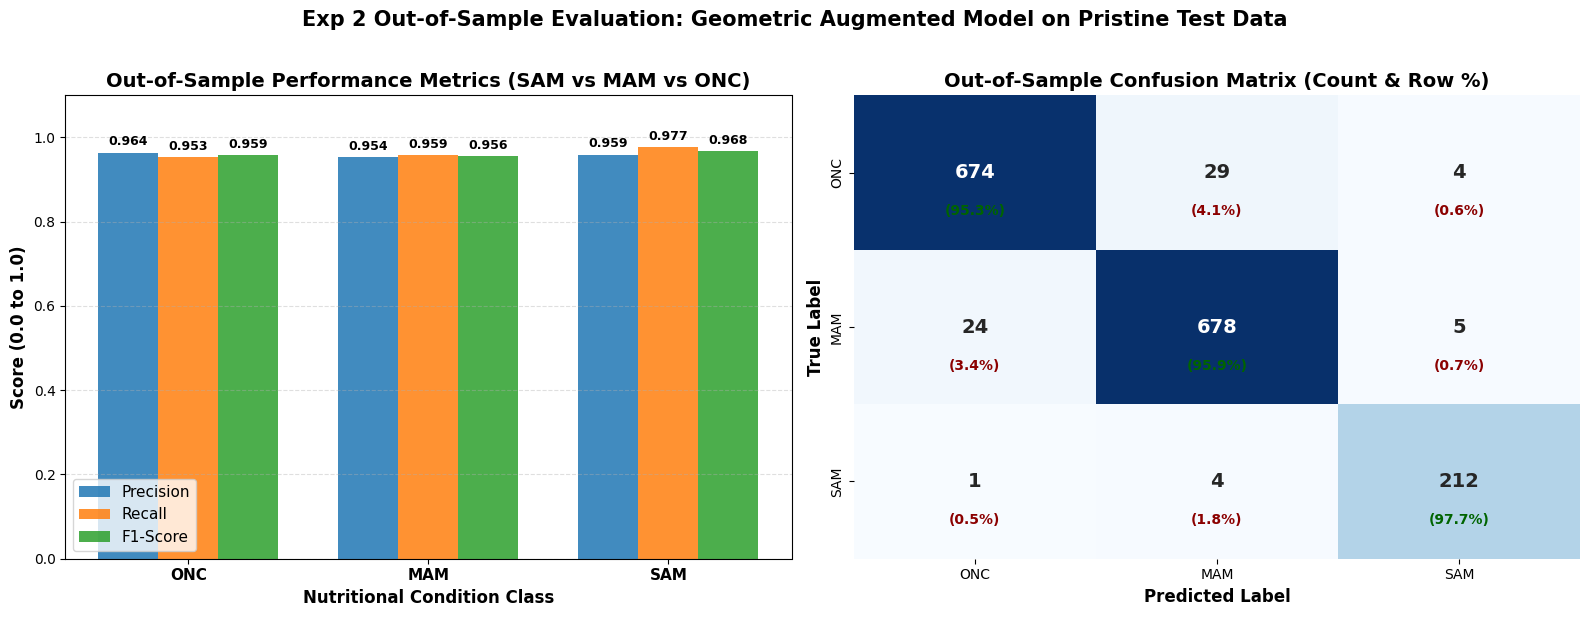

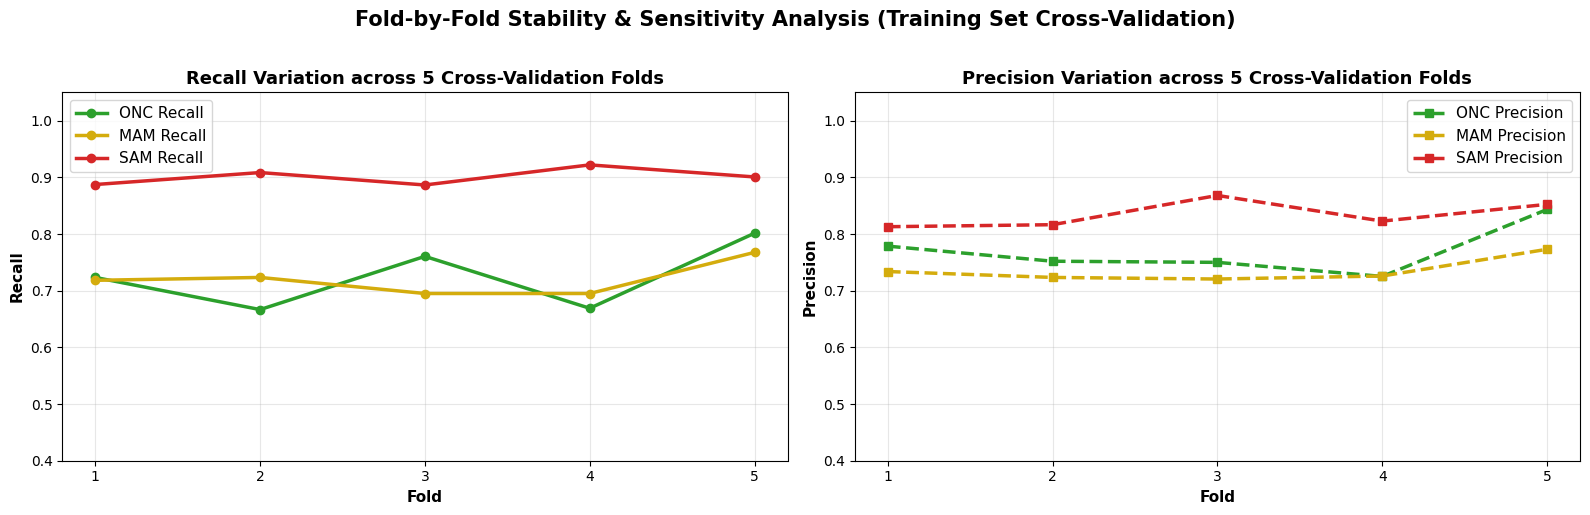

In [9]:
# Precision, Recall & F1-Score Comparison Plot Across All Classes (SAM, MAM, ONC)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Grouped Bar Chart for Out-of-Sample Precision, Recall, and F1-Score
x = np.arange(len(class_names))
width = 0.25

rects1 = axes[0].bar(x - width, df_metrics_oos['Precision'], width, label='Precision', color='#1f77b4', alpha=0.85)
rects2 = axes[0].bar(x, df_metrics_oos['Recall'], width, label='Recall', color='#ff7f0e', alpha=0.85)
rects3 = axes[0].bar(x + width, df_metrics_oos['F1-Score'], width, label='F1-Score', color='#2ca02c', alpha=0.85)

axes[0].set_title('Out-of-Sample Performance Metrics (SAM vs MAM vs ONC)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Nutritional Condition Class', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Score (0.0 to 1.0)', fontsize=12, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(class_names, fontsize=11, fontweight='bold')
axes[0].legend(fontsize=11)
axes[0].set_ylim(0, 1.1)
axes[0].grid(True, linestyle='--', alpha=0.4, axis='y')

# Add values above bars
def autolabel(rects, ax):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.3f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

autolabel(rects1, axes[0])
autolabel(rects2, axes[0])
autolabel(rects3, axes[0])

# Plot 2: Out-of-Sample Confusion Matrix Heatmap
cm_norm_oos = cm_oos.astype('float') / cm_oos.sum(axis=1)[:, np.newaxis]

sns.heatmap(cm_oos, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=class_names, yticklabels=class_names, cbar=False,
            annot_kws={'size': 14, 'weight': 'bold'})

for i in range(len(class_names)):
    for j in range(len(class_names)):
        axes[1].text(j + 0.5, i + 0.75, f"({cm_norm_oos[i, j]*100:.1f}%)",
                     ha='center', va='center', color='darkred' if i != j else 'darkgreen',
                     fontsize=10, fontweight='bold')

axes[1].set_title('Out-of-Sample Confusion Matrix (Count & Row %)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Predicted Label', fontsize=12, fontweight='bold')
axes[1].set_ylabel('True Label', fontsize=12, fontweight='bold')

plt.suptitle('Exp 2 Out-of-Sample Evaluation: Geometric Augmented Model on Pristine Test Data', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Plot 3: Fold-by-Fold Recall & Precision Breakdown (Cross-Validation)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
folds = np.arange(1, 6)

for cls, color in zip(class_names, ['#2ca02c', '#d4ac0d', '#d62728']):
    axes[0].plot(folds, per_class_recalls[cls], marker='o', linewidth=2.5, label=f'{cls} Recall', color=color)
    axes[1].plot(folds, per_class_precisions[cls], marker='s', linestyle='--', linewidth=2.5, label=f'{cls} Precision', color=color)

axes[0].set_title('Recall Variation across 5 Cross-Validation Folds', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Fold', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Recall', fontsize=11, fontweight='bold')
axes[0].set_xticks(folds)
axes[0].set_ylim(0.4, 1.05)
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=11)

axes[1].set_title('Precision Variation across 5 Cross-Validation Folds', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Fold', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Precision', fontsize=11, fontweight='bold')
axes[1].set_xticks(folds)
axes[1].set_ylim(0.4, 1.05)
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=11)

plt.suptitle('Fold-by-Fold Stability & Sensitivity Analysis (Training Set Cross-Validation)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()